# Inlämningsuppgift: Del 1 - Adversarial input attack

Rasmus Eliasson \
rael23@student.bth.se

Oskar Flodin \
osfl22@student.bth.se

# Instruktioner

Ändra notebookens platshållare så som era namn- och mailuppgifter samt instruktioner i de olika avsnitten. 

Notebookens underrubriker på nivå 3 (###) är bara ett enkelt exempel på hur er implementation kan delas upp. Ni bör skapa egna rubriker anpassade efter er implementation men lämna alla nivå 1 (#) och 2-rubriker (##) som de är. En viktig del inom data-science är att kunna presentera sina metoder och resultat på ett tydligt sätt. **En ostrukturerad och otydlig notebook kan påverka betygsättningen.**

Notera att t.ex. hyperparameter-tuning och annan optimisering för prestanda inte är nödvändigt i denna uppgift. Så länge modellen fungerar märkvärt bättre än ett "coin flip" så räcker det att ni väljer era hyperparametrar manuellt.

# Uppgiften

Uppgiften går ut på att göra så att bilden på koalan nedan klassificeras som en traktor istället. Givetvis ska bilden på koalan se helt oförändrad ut för det mänskliga ögat då attacken är genomförd. Nedan följer Pythonkod som läser in de båda bilderna som uppgiften bygger på samt läser in en ResNet50-modell som klassiciferar bilderna. Saknar ni några Python-paket, t.ex. TensorFlow så installera dem med en pakethanterarare, t.ex. pip

## Beskrivning av adversarial input attacker

## Nedan följer kod för att läsa in bilderna och klassificera dem med ResNet50 modellen

In [1]:
# import adversarial
from matplotlib import pyplot as plt
import numpy as np

import tensorflow as tf
import keras
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing import image

from art.estimators.classification import KerasClassifier
from art.attacks.evasion import BoundaryAttack
from art.utils import to_categorical

# Old tensorflow
# tf.compat.v1.disable_eager_execution()

print(f"TensorFlow: {tf.__version__}")
import art
print("ART version:", art.__version__)

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'


TensorFlow: 2.15.1
ART version: 1.20.1


In [2]:
# Loads the pretrained ResNet50 model
model = ResNet50(weights='imagenet')

In [3]:
# Load the two images (koala & tractor)
init_image = image.load_img("images/koala.jpeg", target_size=(224, 224))
init_image = image.img_to_array(init_image)

target_image = image.load_img("images/tractor.jpeg", target_size=(224, 224))
target_image = image.img_to_array(target_image)

class_lookup = {105: "koala", 866: "tractor"}

1/1 [==============================] - 3s 3s/step
Init image class label: 105 (koala)


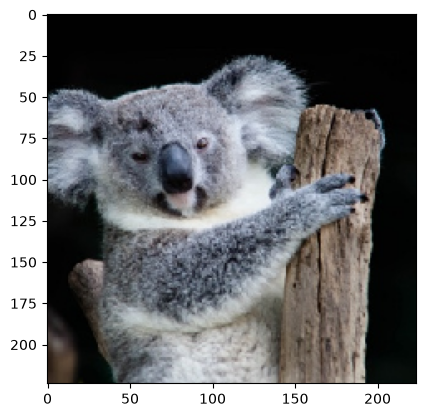

1/1 [==============================] - 0s 163ms/step
Target image class label: 866 (tractor)


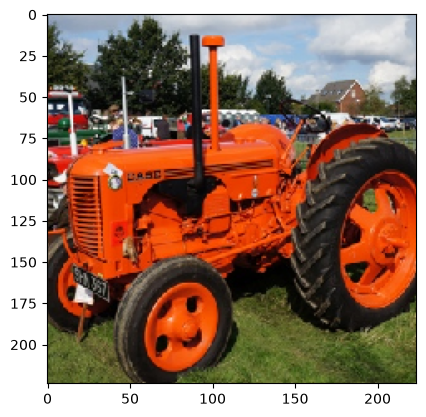

In [4]:
init_class_id = np.argmax(model.predict(np.array([init_image])))
print(f"Init image class label: {init_class_id} ({class_lookup[init_class_id]})")
plt.imshow(init_image.astype(np.uint))
plt.show()

target_class_id = np.argmax(model.predict(np.array([target_image])))
print(f"Target image class label: {target_class_id} ({class_lookup[target_class_id]})")
plt.imshow(target_image.astype(np.uint))
plt.show()

## Implementation av er attack

## Kod för attacken

### Bibliotek

In [ ]:
from art.attacks.evasion import ProjectedGradientDescent
from art.estimators.classification import TensorFlowV2Classifier


### Egna funktioner

In [6]:
# # Gör om rgb-bilder till bgr eftersom ResNet50 är tränat på bilder där pixlarna är på den formen.
class convert_to_bgr(tf.keras.Model):
    def __init__(self, base):
        super().__init__()
        self.base = base

    def call(self, x, training=False):
        x = preprocess_input(x)
        return self.base(x, training=training)

converted_model = convert_to_bgr(model)



# Grad-CAM for ResNet50
def grad_cam(img, class_id=None):

    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer("conv5_block3_out").output,
            model.output
        ]
    )

    # Same preprocessing as your ART wrapper
    img_tensor = tf.convert_to_tensor(img.copy(), dtype=tf.float32)
    img_processed = preprocess_input(img_tensor)

    with tf.GradientTape() as tape:

        conv_output, predictions = grad_model(
            img_processed, training=False
        )

        if class_id is None:
            class_id = tf.argmax(predictions[0])

        class_score = predictions[:, class_id]

    # Gradient of selected class w.r.t. feature maps
    grads = tape.gradient(class_score, conv_output)

    # Average gradients over spatial dimensions
    weights = tf.reduce_mean(grads, axis=(1, 2))

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_output[0] * weights[0],
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    # Normalize to [0, 1]
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    # Resize to original image dimensions
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (224, 224)
    )

    return heatmap.numpy().squeeze()

### Förberedelser

In [7]:
print(model.output_shape)
print(model.input_shape)
print(init_image.min(), init_image.max())
# print(target.shape)

(None, 1000)
(None, 224, 224, 3)
0.0 249.0


In [8]:
classifier = TensorFlowV2Classifier(
    model=converted_model,
    nb_classes=1000,
    input_shape=(224, 224, 3),
    loss_object=keras.losses.CategoricalCrossentropy(from_logits=False),
    clip_values=(0, 255),
)


### Modellering

In [9]:

pgd_attack = ProjectedGradientDescent(
    estimator=classifier,
    eps=8,
    verbose=True,
    targeted=True,
    max_iter=40,
)

### Attack

<hr>
<center>
<h2>
Attackprocessen
</h2>
</center>

<p>
Vi använder en riktad Projected Gradient Descent (PGD)-attack för att få ResNet50 att klassificera en koalabild som en traktor.

Attacken använder modellens gradienter för att iterativt modifiera bildens pixelvärden. Vi använder 40 iterationer och begränsar
förändringen till ε = 8 enligt L∞-normen.

Målet är att ändra modellens klassificering utan att bilden förändras märkbart för det mänskliga ögat.
</p>

In [10]:
# Koalabilden med batch-dimension: (1, 224, 224, 3)
x = np.expand_dims(init_image, axis=0).astype(np.float32)

# Målklassen traktor som one-hot-vektor
target = to_categorical([target_class_id], nb_classes=1000)

adv_image = pgd_attack.generate(
    x=x,
    y=target
)


PGD - Batches: 0it [00:00, ?it/s]

### Attackresultat

<hr>
<p>
Före attacken klassificerades bilden som en koala med 99,82 % prediktionskonfidens. Efter attacken klassificerades den modifierade bilden som en traktor med en prediktionskonfidens som avrundades till 100 %.

Bilden är också fortfarande visuellt lik originalet för det mänskliga ögat, trots den förändrade klassificeringen.
</p>

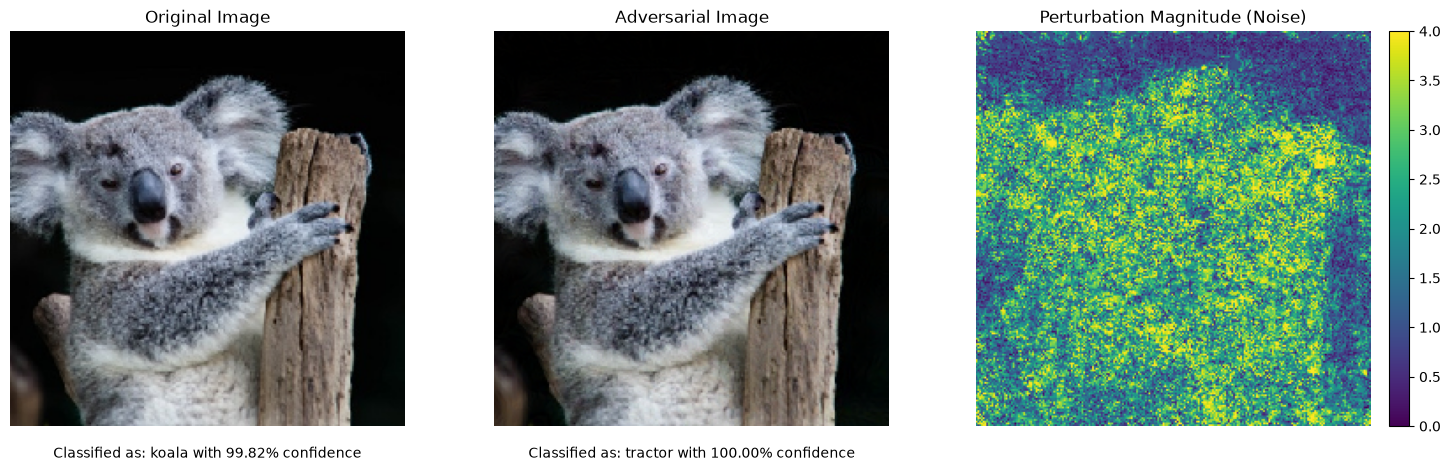

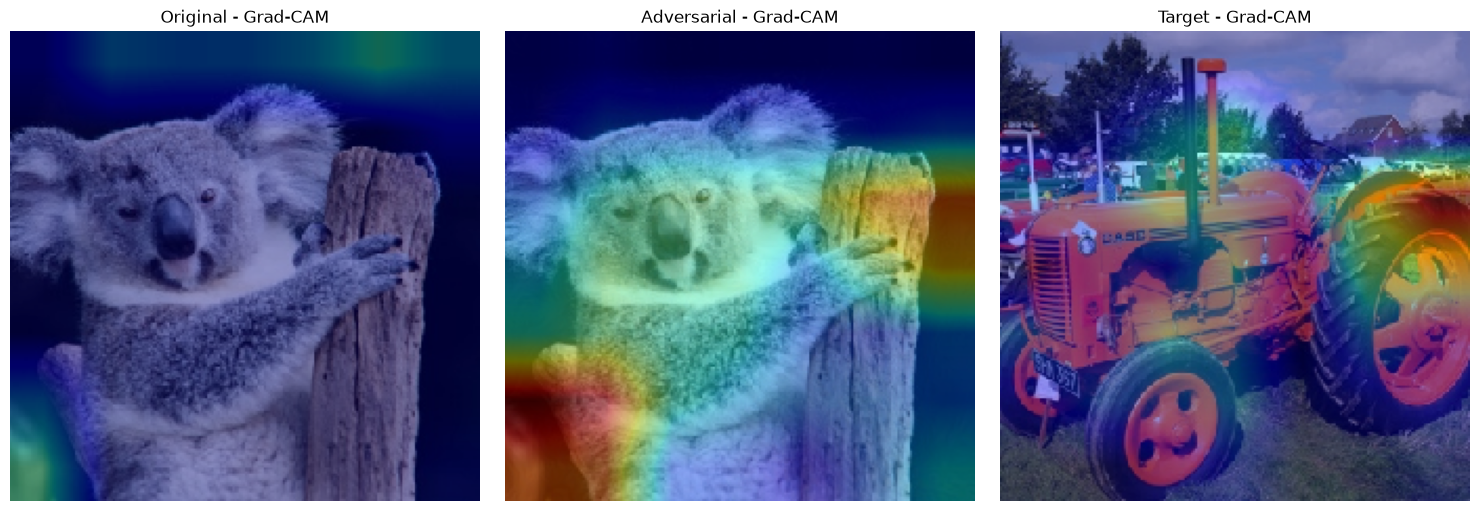

In [11]:
original_pred = classifier.predict(x)
adversarial_pred = classifier.predict(adv_image)

# Get predicted classes
original_class = int(np.argmax(original_pred))
adversarial_class = int(np.argmax(adversarial_pred))

# Get confidence for predicted classes
original_confidence = original_pred[0, original_class]
adversarial_confidence = adversarial_pred[0, adversarial_class]



# Visualisera attackens resultat
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# Calculate perturbation
diff = adv_image[0] - x[0]

# Calculate absolute perturbation magnitude
diff_magnitude = np.max(np.abs(diff), axis=-1)

# Original image
ax[0].imshow(init_image.astype(np.uint8))
ax[0].set_title("Original Image")
ax[0].text(
    0.5, -0.08,
    f"Classified as: {class_lookup.get(original_class, original_class)} with {original_confidence *100:.2f}% confidence",
    transform=ax[0].transAxes,
    ha="center"
)
ax[0].axis("off")


# Adversarial image
ax[1].imshow(np.clip(adv_image[0], 0, 255).astype(np.uint8))
ax[1].set_title("Adversarial Image")
ax[1].text(
    0.5, -0.08,
    f"Classified as: {class_lookup.get(adversarial_class, adversarial_class)} with {adversarial_confidence*100:.2f}% confidence",
    transform=ax[1].transAxes,
    ha="center"
)
ax[1].axis("off")


# Perturbation (enhanced visualization)
im = ax[2].imshow(diff_magnitude)
ax[2].set_title("Perturbation Magnitude (Noise)")
ax[2].axis("off")

fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.subplots_adjust(bottom=0.18)
plt.show()




########################################
# Visualisera hur den fattar sina beslut mot traktor i alla bilderna.
########################################
target_x = np.expand_dims(target_image.copy(), axis=0).astype(np.float32)

cam_original = grad_cam(x, class_id=target_class_id)
cam_adversarial = grad_cam(adv_image, class_id=target_class_id)
cam_target = grad_cam(target_x, class_id=target_class_id)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# Original image
ax[0].imshow(x[0].astype(np.uint8))
ax[0].imshow(cam_original, cmap="jet", alpha=0.4, vmin=0, vmax=1)
ax[0].set_title("Original - Grad-CAM")
ax[0].axis("off")

# Adversarial image
ax[1].imshow(np.clip(adv_image[0], 0, 255).astype(np.uint8))
ax[1].imshow(cam_adversarial, cmap="jet", alpha=0.4, vmin=0, vmax=1)
ax[1].set_title("Adversarial - Grad-CAM")
ax[1].axis("off")

# Target image
ax[2].imshow(target_x[0].astype(np.uint8))
ax[2].imshow(cam_target, cmap="jet", alpha=0.4, vmin=0, vmax=1)
ax[2].set_title("Target - Grad-CAM")
ax[2].axis("off")

plt.tight_layout()
plt.show()

## Skyddsåtgärder

<p>
Vi valde Feature Squeezing som försvar mot vår PGD-attack. Metoden använder bildtransformationer för att upptäcka förändringar i modellens prediktioner.

Vi valde metoden eftersom den inte kräver någon ytterligare träning av modellen, till skillnad från exempelvis adversarial training.
</p>

<hr>
<hr>

## Implementation av skyddsåtgärder (frivilligt endast för A eller B)

### Egna funktioner

In [12]:
from scipy.ndimage import median_filter

# Squeezer 1: Reduce bit depth
def bit_depth_reduction(img, bits=5):
    levels = 2**bits - 1
    return np.round(img / 255 * levels) / levels * 255


# Squeezer 2: Spatial smoothing
def spatial_smoothing(img):
    return median_filter(img, size=(1, 3, 3, 1))


def split_into_three(input_img):
    reduct_bit_depth = bit_depth_reduction(input_img.copy())
    spatial_smoth = spatial_smoothing(input_img.copy())

    return (input_img, reduct_bit_depth, spatial_smoth)


def calculate_pcm_distance(input_img):

    # Generate the three versions
    original, bits, smooth = split_into_three(input_img)

    # Get model predictions for each version
    p_original = classifier.predict(original)
    p_bits = classifier.predict(bits)
    p_smooth = classifier.predict(smooth)

    # Calculate L1 distances between predictions
    d1 = np.sum(np.abs(p_original - p_bits))
    d2 = np.sum(np.abs(p_original - p_smooth))

    # Get the maximum distance of the two.
    distance = max(d1, d2)

    print("Bit-depth distance:", d1)
    print("Smoothing distance:", d2)
    print("Maximum distance:", distance)

    return distance


### Förberedelser

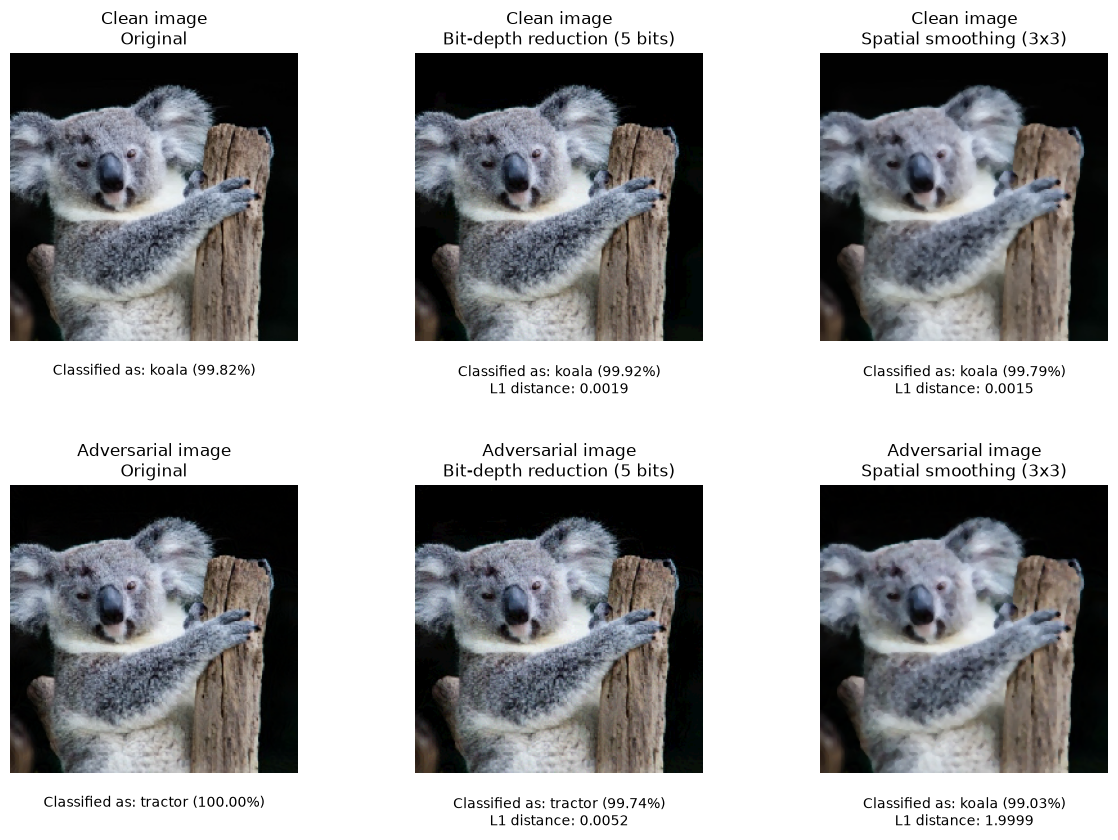

In [13]:
# Visualize Feature Squeezing results

images = [
    ("Clean image", x),
    ("Adversarial image", adv_image)
]

transformation_names = [
    "Original",
    "Bit-depth reduction (5 bits)",
    "Spatial smoothing (3x3)"
]

fig, ax = plt.subplots(2, 3, figsize=(15, 9))

for row, (image_name, input_img) in enumerate(images):

    # Generate the three versions using our existing function
    image_versions = split_into_three(input_img)

    predictions = []

    for col, (title, img) in enumerate(zip(transformation_names, image_versions)):

        # Predict
        pred = classifier.predict(img.astype(np.float32))
        predictions.append(pred)

        # Get predicted class and confidence
        class_id = int(np.argmax(pred[0]))
        class_name = class_lookup.get(class_id, f"Class {class_id}")
        confidence = pred[0, class_id]

        # Display image
        ax[row, col].imshow(
            np.clip(img[0], 0, 255).astype(np.uint8)
        )

        ax[row, col].set_title(f"{image_name}\n{title}")
        ax[row, col].axis("off")

        # Classification text
        text = f"Classified as: {class_name} ({confidence:.2%})"

        # Calculate L1 distance against the original prediction
        if col > 0:
            distance = np.sum(np.abs(predictions[0] - pred))
            text += f"\nL1 distance: {distance:.4f}"

        # Display text underneath each image
        ax[row, col].text(
            0.5, -0.08,
            text,
            transform=ax[row, col].transAxes,
            ha="center",
            va="top",
            fontsize=10
        )

plt.subplots_adjust(hspace=0.5, wspace=0.15, bottom=0.08)
plt.show()

### Skydd

<hr>
<p>
Som försvar använder vi Feature Squeezing med två transformationer:
<code>bit-depth reduction</code> (5 bitar) och <code>spatial smoothing</code> (3 × 3-medianfilter).

För varje transformation jämför vi modellens prediktionsvektor med prediktionen från den ursprungliga bilden. Skillnaden
beräknas med L1-avstånd, och det största avståndet används för att upptäcka möjliga attacker.

Om avståndet överstiger tröskelvärdet 0,25 flaggas bilden som potentiellt attackerad.
</p>

In [14]:
# Implementation av skyddsåtgärd

def detect_attack(values, threshold = 0.25):
    # print()
    if values > threshold:
        print("Alert!! Probabbly an adversal attack image.")
    else:
        print("Safe!")


### Skyddsresultat

<hr>
<p>
För den rena koalabilden uppmättes ett maximalt L1-avstånd på 0,0019, medan den attackerade bilden gav 1,9999. Med tröskelvärdet 0,25 flaggades den attackerade bilden, men inte originalbilden.

Efter spatial smoothing klassificerade modellen dessutom den attackerade bilden som en koala igen, med ungefär 99 % prediktionskonfidens.

Resultatet demonstrerar att skyddet fungerade för denna attack, men visar inte att det är robust mot andra eller anpassade attacker.
</p>

In [ ]:
threshold = 0.25

print("Original image")
d_clean = calculate_pcm_distance(x)

print("\nAttack: adv image")
d_adv = calculate_pcm_distance(adv_image)
print("=" * 30, end="\n"*2)

print("Original safe image")
detect_attack(d_clean, threshold)


print("\nAdversial image")
detect_attack(d_adv, threshold)



Original image
Bit-depth distance: 0.0019097216
Smoothing distance: 0.0014603419
Maximum distance: 0.0019097216

Attack: adv image
Bit-depth distance: 0.005236156
Smoothing distance: 1.999926
Maximum distance: 1.999926

Original safe image
Safe!

Adversial image
Alert!! Probabbly an adversal attack image.


# Referenser

- Selvaraju et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization*. Proceedings of the IEEE International Conference on Computer Vision (ICCV). [Paper](https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html)